# Exploración de datos (EDA) – Iris

**Materia:** Operaciones de aprendizaje automático (MLOps)

**Alumno:** Jesus Alvizo Morneo - A01411061

**Dataset:** Iris

Este notebook se usa **solo para explorar y entender los datos** (carga, EDA y decisiones de limpieza).
El entrenamiento, la evaluación y el registro en MLflow están en el script `mna_exp_mlflow/modeling/train.py`, que se ejecuta desde la línea de comandos.

In [ ]:
# Librerías
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Carpeta para guardar las gráficas del EDA
os.makedirs("figuras", exist_ok=True)

## Paso 1. Carga y descripción del dataset

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Renombramos las columnas a nombres cortos en español
df.columns = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo", "target"]

# Agregamos el nombre de la especie para que sea más fácil de leer
df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))

df.head()

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,target,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print("Registros y columnas:", df.shape)
print()
df.info()

Registros y columnas: (150, 6)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   largo_sepalo  150 non-null    float64
 1   ancho_sepalo  150 non-null    float64
 2   largo_petalo  150 non-null    float64
 3   ancho_petalo  150 non-null    float64
 4   target        150 non-null    int64  
 5   especie       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB


**Descripción de la estructura**

- **Registros:** 150 flores (50 de cada especie).
- **Variables de entrada (4, numéricas `float64`, en centímetros):**

| Variable | Significado |
|---|---|
| `largo_sepalo` | Largo del sépalo (hoja exterior verde que protege la flor) |
| `ancho_sepalo` | Ancho del sépalo |
| `largo_petalo` | Largo del pétalo (hoja interior de color) |
| `ancho_petalo` | Ancho del pétalo |

- **Variable objetivo:** `target` (entero 0, 1, 2) con su nombre en `especie`: *setosa*, *versicolor* y *virginica*.
- **Tipo de problema:** clasificación supervisada **multiclase** (3 clases).

## Paso 2. Análisis exploratorio (EDA)

### 2.1 Estadísticas descriptivas

In [4]:
df.describe().round(2)

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


In [5]:
# ¿Están balanceadas las clases?
df["especie"].value_counts()

especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [6]:
# Promedio de cada medida por especie
df.groupby("especie")[["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo"]].mean().round(2)

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
especie,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


### 2.2 Visualizaciones

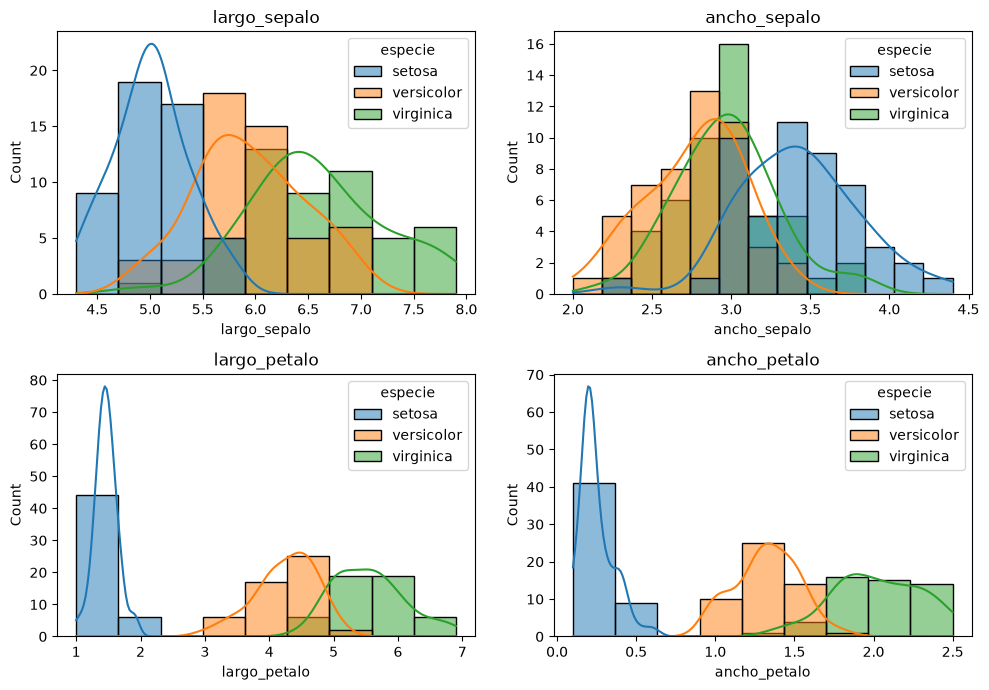

In [7]:
# Distribución de cada variable por especie
features = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="especie", kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("figuras/histogramas.png", dpi=100)
plt.show()

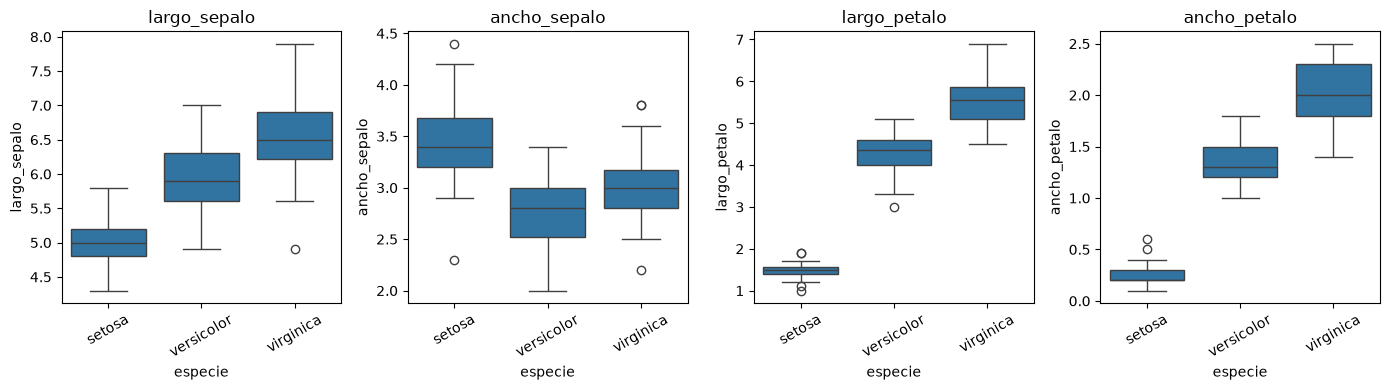

In [8]:
# Boxplots: sirven para comparar especies y detectar outliers
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="especie", y=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figuras/boxplots.png", dpi=100)
plt.show()

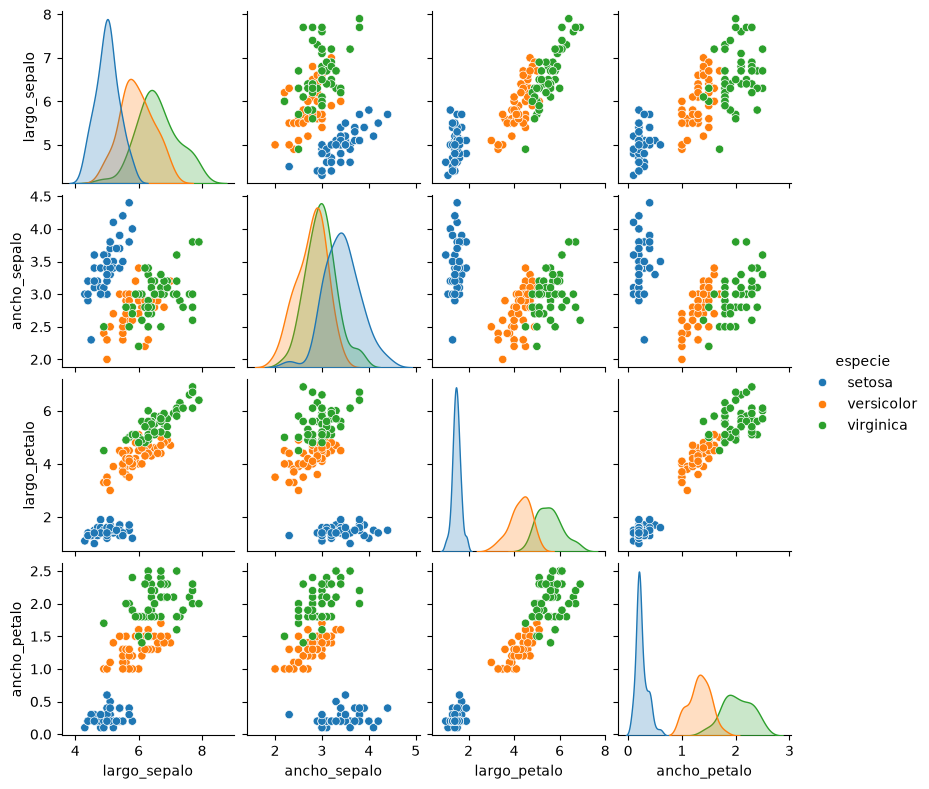

In [9]:
# Relaciones entre pares de variables
g = sns.pairplot(df[features + ["especie"]], hue="especie", height=2)
g.savefig("figuras/pairplot.png", dpi=100)
plt.show()

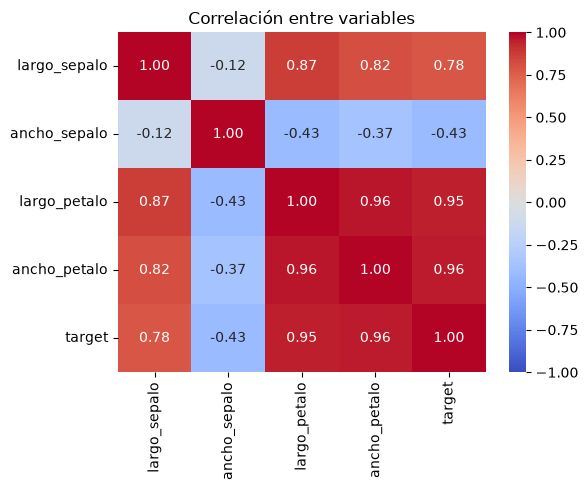

In [10]:
# Matriz de correlación
plt.figure(figsize=(6, 5))
sns.heatmap(df[features + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.tight_layout()
plt.savefig("figuras/correlacion.png", dpi=100)
plt.show()

**Hallazgos del EDA**

- Las clases están perfectamente balanceadas (50 por especie), así que el accuracy es una métrica confiable para este problema.
- Las medidas del pétalo son las más informativas: *setosa* tiene pétalos mucho más pequeños y queda completamente separada de las otras dos especies en el pairplot.
- *Versicolor* y *virginica* se traslapan un poco, sobre todo en las medidas del sépalo. Probablemente el modelo cometa algunos errores en esta parte.
- `largo_petalo` y `ancho_petalo` tienen una correlación muy alta entre sí (≈ 0.96) y con la clase. `ancho_sepalo` es la variable menos relacionada con las demás.
- Los boxplots muestran algunos puntos fuera de los bigotes, principalmente en `ancho_sepalo`.

## Paso 3. Limpieza de datos

Se revisan cuatro aspectos: valores faltantes, duplicados, tipos de datos y outliers.

In [11]:
# 3.1 Valores faltantes
df.isna().sum()

largo_sepalo    0
ancho_sepalo    0
largo_petalo    0
ancho_petalo    0
target          0
especie         0
dtype: int64

No hay valores faltantes, por lo que no se requiere imputación ni eliminación.

In [12]:
# 3.2 Duplicados
print("Filas duplicadas:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Filas duplicadas: 1


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,target,especie
101,5.8,2.7,5.1,1.9,2,virginica
142,5.8,2.7,5.1,1.9,2,virginica


In [13]:
df = df.drop_duplicates().reset_index(drop=True)
print("Registros después de quitar duplicados:", len(df))

Registros después de quitar duplicados: 149


Se encontró 1 fila duplicada (una *virginica* con exactamente las mismas cuatro medidas). Se elimina para evitar que el mismo registro quede al mismo tiempo en entrenamiento y en prueba, lo que inflaría artificialmente la métrica. Perder 1 de 150 registros no afecta el balance de clases.

In [14]:
# 3.3 Tipos de datos
print(df.dtypes)

# La especie es una variable categórica, no texto libre
df["especie"] = df["especie"].astype("category")

largo_sepalo    float64
ancho_sepalo    float64
largo_petalo    float64
ancho_petalo    float64
target            int64
especie             str
dtype: object


Las cuatro medidas ya son `float64` y el `target` es entero, que es lo correcto. Solo se convierte `especie` a tipo `category`, porque representa un conjunto fijo de valores.

In [15]:
# 3.4 Outliers con el método del rango intercuartílico (IQR)
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < limite_inf) | (df[col] > limite_sup)]
    print(f"{col}: {len(outliers)} outliers -> {outliers[col].tolist()}")

largo_sepalo: 0 outliers -> []
ancho_sepalo: 4 outliers -> [4.4, 4.1, 4.2, 2.0]
largo_petalo: 0 outliers -> []
ancho_petalo: 0 outliers -> []


Solo `ancho_sepalo` tiene outliers (4 valores: 2.0, 4.1, 4.2 y 4.4 cm). Se conservan porque:

1. Son medidas físicamente posibles para una flor, no errores de captura.
2. Los tres valores altos (4.1, 4.2 y 4.4) son de *setosa*, que naturalmente tiene sépalos más anchos, y el valor bajo (2.0) es de una *versicolor*. Es variación real entre especies y dentro de ellas.
3. Con solo 149 registros, eliminar datos válidos reduce información útil para el modelo.

Resumen de limpieza: 0 faltantes, 1 duplicado eliminado, tipos correctos (solo se ajustó `especie`), outliers conservados. Dataset final: 149 registros.

## Siguiente paso: entrenamiento en `mna_exp_mlflow/modeling/train.py`

Las decisiones de limpieza de este notebook (sin faltantes, eliminar 1 duplicado, conservar outliers) están implementadas en la función `cargar_datos()` de `mna_exp_mlflow/modeling/train.py`.

Para entrenar y registrar corridas en MLflow (desde la raíz del proyecto):

```
python mna_exp_mlflow/modeling/train.py          # valores por defecto
python mna_exp_mlflow/modeling/train.py --C 10   # cambiando hiperparámetros
```

La lista de las 9 corridas del experimento está en el `README.md`.